# PRCP 1025-Flight Price Prediction

## Final Project Notebook

This notebook completes the required project work for PRCP-2025-FlightPricePrediction using the Flight Fare dataset. It includes data analysis, data preprocessing, feature engineering, categorical encoding, regression model comparison, best model selection, hyperparameter tuning, flight fare prediction, challenges faced, and final conclusions.



## Problem Statement

The objective of this project is to predict flight ticket prices using important factors such as airline, source, destination, journey date, duration, and number of stops.Since Price is a continuous value, this is a supervised regression problem. The goal is to develop a machine learning model that can predict flight fares accurately.


In [ ]:
#Import the tools needed for data handling, visualization, preprocessing, model comparison, evaluation, and saving the complete pipeline.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
import os

print(os.listdir())

['.config', 'sample_data']


## 1) Load Dataset

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_excel('/content/drive/MyDrive/Bidya/datamites_priject _dataset/Flight_Fare.xlsx')

In [ ]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [ ]:
df.shape

(10683, 11)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [ ]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


## 3) Data Cleaning

In [ ]:
df.isnull().sum()

,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,1
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,1
Additional_Info,0


In [ ]:
df.nunique()

,0
Airline,12
Date_of_Journey,44
Source,5
Destination,6
Route,128
Dep_Time,222
Arrival_Time,1343
Duration,368
Total_Stops,5
Additional_Info,10


In [ ]:
# 1. Check number of duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

# 2. Display duplicate rows
duplicates = df[df.duplicated(keep=False)]
duplicates

Number of duplicate rows: 220


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
33,Jet Airways,15/06/2019,Delhi,Cochin,DEL → NAG → BOM → COK,14:35,12:35 16 Jun,22h,2 stops,In-flight meal not included,10919
49,Jet Airways,27/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,19:00 28 Jun,19h 55m,2 stops,In-flight meal not included,11150
73,Jet Airways,24/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,12:35 25 Jun,13h 30m,2 stops,No info,12819
81,Jet Airways,24/03/2019,Banglore,New Delhi,BLR → DEL,19:55,22:35,2h 40m,non-stop,No info,7229
87,Jet Airways,6/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,09:40,04:25 07 Jun,18h 45m,2 stops,No info,13014
...,...,...,...,...,...,...,...,...,...,...,...
10594,Jet Airways,27/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,12:35 28 Jun,13h 30m,2 stops,No info,12819
10616,Jet Airways,1/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,09:40,12:35 02 Jun,26h 55m,2 stops,No info,13014
10634,Jet Airways,6/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,09:40,12:35 07 Jun,26h 55m,2 stops,In-flight meal not included,11733
10672,Jet Airways,27/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,19:00 28 Jun,19h 55m,2 stops,In-flight meal not included,11150


In [ ]:
# 3. Remove duplicate rows
df = df.drop_duplicates()

# 4. Check the shape after removing duplicates
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (10463, 11)


## 4) Exploratory Data Analysis

In [ ]:
X = df.drop("Price", axis=1)

y = df["Price"]

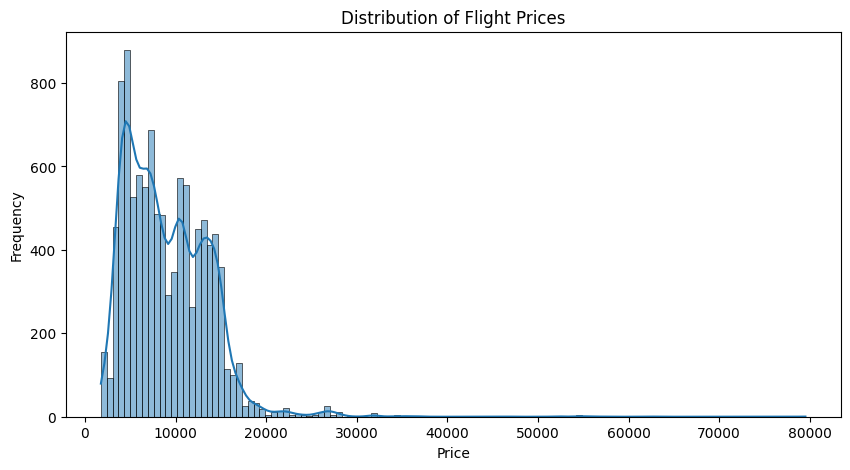

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Price"], kde=True)

plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

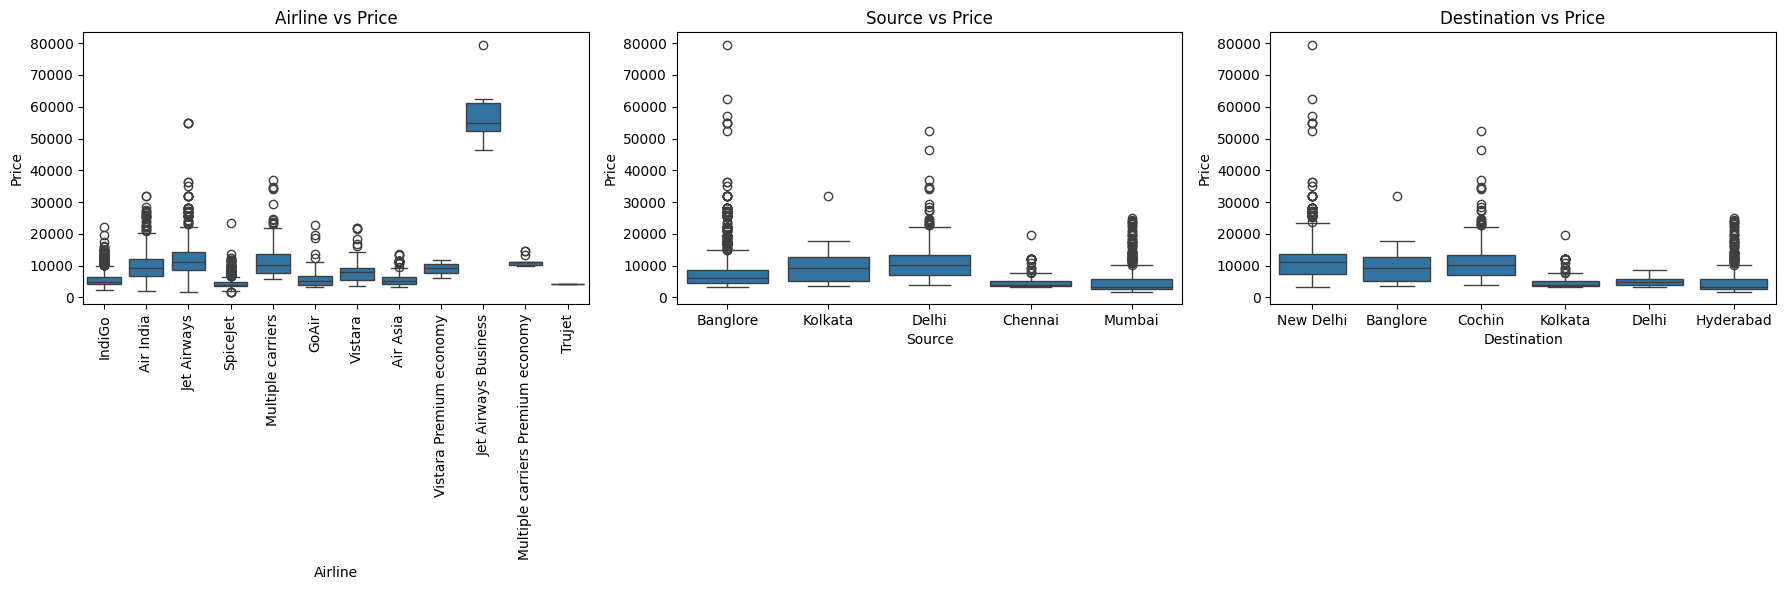

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Airline vs Price
sns.boxplot(
    data=df,
    x="Airline",
    y="Price",
    ax=axes[0]
)

axes[0].set_title("Airline vs Price")
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_xlabel("Airline")
axes[0].set_ylabel("Price")


# 2. Source vs Price
sns.boxplot(
    data=df,
    x="Source",
    y="Price",
    ax=axes[1]
)

axes[1].set_title("Source vs Price")
axes[1].set_xlabel("Source")
axes[1].set_ylabel("Price")


# 3. Destination vs Price
sns.boxplot(
    data=df,
    x="Destination",
    y="Price",
    ax=axes[2]
)

axes[2].set_title("Destination vs Price")
axes[2].set_xlabel("Destination")
axes[2].set_ylabel("Price")


plt.tight_layout()
plt.show()

## 5) Feature Engineering

In [ ]:
df = df.copy()
df["Date_of_Journey"] = pd.to_datetime(
    df["Date_of_Journey"],
    format="%d/%m/%Y",
    errors="coerce"
)

In [ ]:
#Extract day, month, year and weekday
df["Journey_Day"] = df["Date_of_Journey"].dt.day
df["Journey_Month"] = df["Date_of_Journey"].dt.month
df["Journey_Year"] = df["Date_of_Journey"].dt.year

df["Journey_Weekday"] = df["Date_of_Journey"].dt.weekday

df["Is_Weekend"] = (
    df["Journey_Weekday"] >= 5
).astype(int)

df.drop("Date_of_Journey", axis=1, inplace=True)

In [ ]:
# Extract departure hour and minute
df["Dep_Hour"] = df["Dep_Time"].apply(
    lambda x: int(x.split(":")[0])
)

df["Dep_Minute"] = df["Dep_Time"].apply(
    lambda x: int(x.split(":")[1])
)
df["Departure_Time_Minutes"] = (
    df["Dep_Hour"] * 60 + df["Dep_Minute"]
)

In [ ]:
# Extract arrival hour and minute
df["Arrival_Hour"] = df["Arrival_Time"].str.extract(
    r"(\d{1,2}):\d{2}"
)[0].astype(int)

df["Arrival_Minute"] = df["Arrival_Time"].str.extract(
    r"\d{1,2}:(\d{2})"
)[0].astype(int)
df["Arrival_Time_Minutes"] = (
    df["Arrival_Hour"] * 60 + df["Arrival_Minute"]
)

In [ ]:
def duration_to_minutes(duration):
    hours = 0
    minutes = 0

    if "h" in duration:
        hours = int(duration.split("h")[0])

    if "m" in duration:
        if "h" in duration:
            minutes = int(
                duration.split("h")[1]
                .replace("m", "")
                .strip()
            )
        else:
            minutes = int(
                duration.replace("m", "").strip()
            )

    return hours * 60 + minutes


df["Duration_Minutes"] = df["Duration"].apply(
    duration_to_minutes
)

df.drop("Duration", axis=1, inplace=True)

In [ ]:
#Convert Total Stops
stop_mapping = {
    "non-stop": 0,
    "1 stop": 1,
    "2 stops": 2,
    "3 stops": 3,
    "4 stops": 4
}

df["Total_Stops"] = df["Total_Stops"].map(
    stop_mapping
)

In [ ]:
#Handle the missing value
df["Total_Stops"] = df["Total_Stops"].fillna(
    df["Total_Stops"].median()
)

In [ ]:
df.drop(
    ["Dep_Time", "Arrival_Time"],
    axis=1,
    inplace=True
)

In [ ]:
# I removed it from the dataset.Because the column is highly dominated by "No info",
#its categories are highly imbalanced and the rare categories provide very little reliable information.
df.drop(
    "Additional_Info",
    axis=1,
    inplace=True
)

In [ ]:
#Create time buckets
def time_bucket(hour):

    if hour < 6:
        return "Early Morning"

    elif hour < 12:
        return "Morning"

    elif hour < 18:
        return "Afternoon"

    elif hour < 22:
        return "Evening"

    else:
        return "Night"

In [ ]:
df["Departure_Time_Bucket"] = df["Dep_Hour"].apply(
    time_bucket
)

df["Arrival_Time_Bucket"] = df["Arrival_Hour"].apply(
    time_bucket
)

## 6) Data Preprocessing

In [ ]:
X = df.drop("Price", axis=1)
y = df["Price"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [ ]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns
print(categorical_columns)

numerical_columns = X.select_dtypes(
    exclude=["object"]
).columns
print(numerical_columns)

Index(['Airline', 'Source', 'Destination', 'Route', 'Departure_Time_Bucket',
       'Arrival_Time_Bucket'],
      dtype='object')
Index(['Total_Stops', 'Journey_Day', 'Journey_Month', 'Journey_Year',
       'Journey_Weekday', 'Is_Weekend', 'Dep_Hour', 'Dep_Minute',
       'Departure_Time_Minutes', 'Arrival_Hour', 'Arrival_Minute',
       'Arrival_Time_Minutes', 'Duration_Minutes'],
      dtype='object')


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

## 7) Model Building & Comparison

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Ridge": Ridge(),
    "XGBoost": XGBRegressor(random_state=42)
}

results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })



## 8) Model Evaluation

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,XGBoost,1144.140137,3.172356e+06,1781.110819,0.847956
1,Random Forest,1150.351079,3.710839e+06,1926.353725,0.822147
2,Gradient Boosting,1526.433860,5.001839e+06,2236.479072,0.760273
3,Decision Tree,1360.541647,5.899456e+06,2428.879481,0.717252
4,Linear Regression,1774.906380,7.027654e+06,2650.972261,0.663180
5,Ridge,1867.967141,7.641038e+06,2764.242694,0.633781


In [ ]:
best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)
print("Best R2 Score:", results_df.iloc[0]["R2 Score"])

Best Model: XGBoost
Best R2 Score: 0.8479557633399963


## 9) Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        random_state=42,
        objective="reg:squarederror"
    ))
])


param_grid = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__gamma": [0, 0.1, 0.2]
}


random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('categorical',
                                                                               OneHotEncoder(handle_unknown='ignore'),
                                                                               Index(['Airline', 'Source', 'Destination', 'Route', 'Departure_Time_Bucket',
       'Arrival_Time_Bucket'],
      dtype='object'))])),
                                             ('model',
                                              XGBRegressor(base_score=None,
                                                           booster=None,
                                                           callback...
                                                           num_parallel_tree=None, ...))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'model__colsample_bytree': [0.7, 0.8,
                                                                    0.9, 1.0],
                                        'model__gamma': [0, 0.1, 0.2],
                                        'model__learning_rate': [0.01, 0.03,
                                                                 0.05, 0.1],
                                        'model__max_depth': [3, 4, 5, 6, 8],
                                        'model__min_child_weight': [1, 3, 5],
                                        'model__n_estimators': [200, 300, 500,
                                                                700],
                                        'model__subsample': [0.7, 0.8, 0.9,
                                                             1.0]},
                   random_state=42, scoring='r2')

In [ ]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation R2:")
print(random_search.best_score_)

Best Parameters:
{'model__subsample': 0.9, 'model__n_estimators': 700, 'model__min_child_weight': 1, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__gamma': 0.2, 'model__colsample_bytree': 0.7}

Best Cross-Validation R2:
0.8510953307151794


## 10) Final Model & Prediction

In [ ]:
best_xgb = random_search.best_estimator_

y_pred_xgb = best_xgb.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_xgb)
mse = mean_squared_error(y_test, y_pred_xgb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_xgb)

print("Tuned XGBoost Results")
print("----------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Tuned XGBoost Results
----------------------
MAE : 1088.1956787109375
MSE : 3030889.25
RMSE: 1740.9449302031353
R2 Score: 0.8547359704971313


## 11. Challenges Faced and Techniques Used

### a) Missing Values

The dataset contained one missing value in the `Route` column and one in the `Total_Stops` column. These missing values were handled using suitable imputation or data-cleaning techniques to ensure the dataset was ready for model training.


### b) Categorical Variables
The dataset contained categorical features such as Airline, Source, Destination, Route, and Additional_Info. These variables were converted into numerical format using encoding techniques so that machine learning models could process them.

### c) Skewed Target Variable
The target variable Price was positively skewed, with some tickets having much higher prices than others. The distribution was examined during EDA. The original price values were retained for prediction, and model performance was evaluated using regression metrics.

### d) Outliers
Outliers were examined using boxplots to identify unusually high flight prices. Since high prices may represent genuine business-class tickets or other flight conditions, they were not automatically removed without proper justification.

### e) Feature Engineering
Feature engineering was performed to extract useful information from the existing columns. Date_of_Journey was split into day, month, and year; departure and arrival times were separated into hours and minutes; and Duration was converted into minutes. Total_Stops was also converted into numerical values.

### f) Model Selection
Different regression models were evaluated using the same training and testing approach. Their performance was compared using R² score, Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE). XGBoost achieved an R² score of approximately 0.83 in the test run, making it a suitable model based on that evaluation.

## 12. Final Conclusion
This project demonstrates an end-to-end machine learning workflow for predicting flight ticket prices. Data cleaning, categorical encoding, feature engineering, and regression model evaluation were performed to build a predictive model. The model achieved an R² score of approximately 0.83 in the evaluated test run. Prediction performance may be limited by the available features and information in the dataset, and further improvements could be explored through additional relevant features and hyperparameter tuning.

## Streamlit App Screenshots

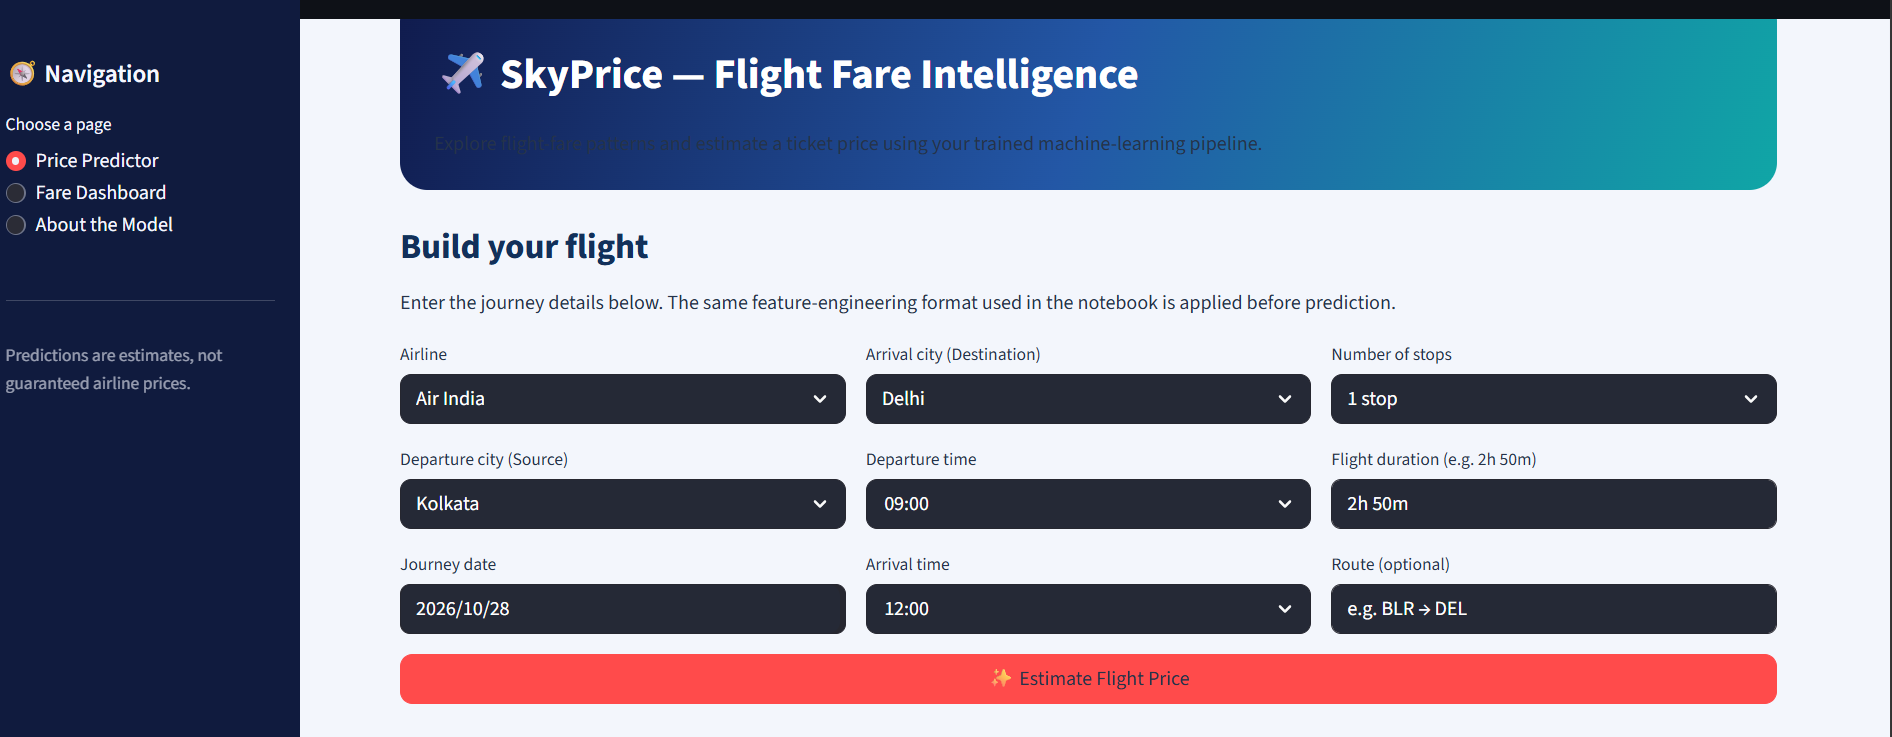

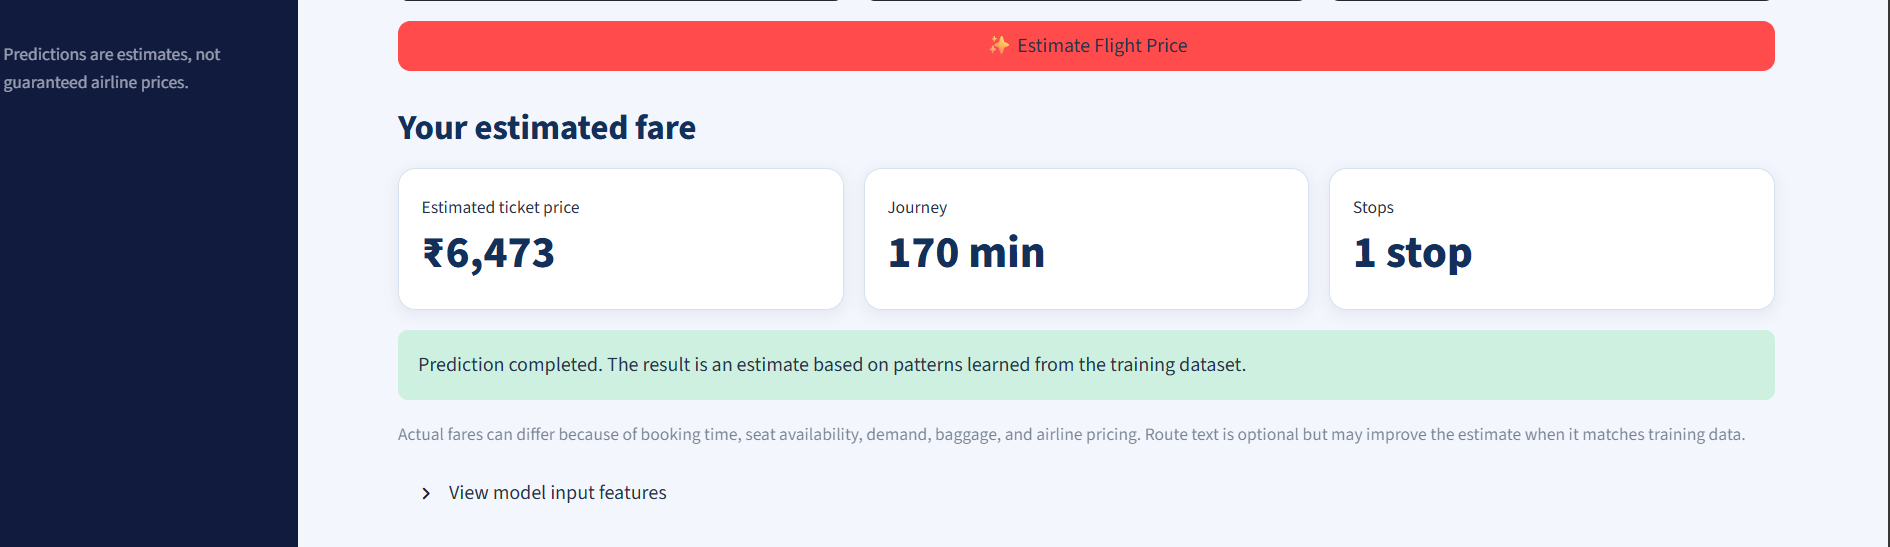

In [ ]:
import os

os.listdir()
from IPython.display import Image, display

display(Image('/content/drive/MyDrive/Bidya/flight image/1.png'))
display(Image('/content/drive/MyDrive/Bidya/flight image/2.png'))



## Streamlit Code

In [ ]:
'''import re
from pathlib import Path
from datetime import date, time, timedelta

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="SkyPrice | Flight Fare Predictor", page_icon="✈️", layout="wide")

# ---------- Styling ----------
st.markdown("""
<style>
/* Strong high-contrast styling for Streamlit light dashboard */
:root { color-scheme: light; }
.stApp, [data-testid="stAppViewContainer"], [data-testid="stMain"] {
    background: #f3f6fc !important;
    color: #172033 !important;
}
[data-testid="stMain"] [data-testid="stMarkdownContainer"],
[data-testid="stMain"] [data-testid="stMarkdownContainer"] p,
[data-testid="stMain"] [data-testid="stMarkdownContainer"] li,
[data-testid="stMain"] [data-testid="stWidgetLabel"],
[data-testid="stMain"] [data-testid="stWidgetLabel"] *,
[data-testid="stMain"] label,
[data-testid="stMain"] small,
[data-testid="stMain"] .stCaption,
[data-testid="stMain"] [data-testid="stCaptionContainer"] {
    color: #25334a !important;
}
[data-testid="stMain"] h1,
[data-testid="stMain"] h2,
[data-testid="stMain"] h3,
[data-testid="stMain"] h4 {
    color: #12305a !important;
    font-weight: 750 !important;
}
.block-container { padding-top: 1.5rem !important; padding-bottom: 2rem !important; }
.hero {
    padding: 1.5rem 1.7rem; border-radius: 22px;
    color: #ffffff !important;
    background: linear-gradient(110deg, #101b4d, #2357a6, #10a6a6);
    margin-bottom: 1rem;
}
.hero h1, .hero p { color: #ffffff !important; }
.hero h1 { margin: 0; font-size: 2.1rem; }
.hero p { margin: .45rem 0 0 0; font-size: 1rem; }
/* Inputs: dark field with readable white selected value */
[data-testid="stMain"] input,
[data-testid="stMain"] textarea {
    color: #ffffff !important; -webkit-text-fill-color: #ffffff !important;
    background-color: #252936 !important; border-radius: 9px !important;
}
[data-testid="stMain"] [data-baseweb="select"] > div {
    color: #ffffff !important; background-color: #252936 !important;
    border-radius: 9px !important;
}
[data-testid="stMain"] [data-baseweb="select"] span,
[data-testid="stMain"] [data-baseweb="select"] input {
    color: #ffffff !important; -webkit-text-fill-color: #ffffff !important;
}
[data-baseweb="popover"], [data-baseweb="menu"] { background: #ffffff !important; }
[data-baseweb="menu"] *, [role="option"] { color: #172033 !important; }
/* Price/result cards */
[data-testid="stMetric"] {
    background: #ffffff !important; padding: 18px !important;
    border-radius: 14px !important; border: 1px solid #d7e2f0 !important;
    box-shadow: 0 3px 12px rgba(26, 43, 75, .08) !important;
}
[data-testid="stMetricLabel"], [data-testid="stMetricLabel"] * {
    color: #526178 !important;
}
[data-testid="stMetricValue"], [data-testid="stMetricValue"] * {
    color: #12305a !important; -webkit-text-fill-color: #12305a !important;
    font-weight: 800 !important;
}
section[data-testid="stSidebar"] { background: #101b3e !important; }
section[data-testid="stSidebar"] * { color: #f5f7ff !important; }
div.stButton > button, [data-testid="stFormSubmitButton"] button {
    border-radius: 10px !important; font-weight: 700 !important;
}
[data-testid="stAlert"] { border-radius: 12px !important; }
</style>
""", unsafe_allow_html=True)

MODEL_PATH = Path(__file__).with_name("flight_price_prediction_pipeline.joblib")
DATA_CANDIDATES = [
    Path(__file__).with_name("Flight_Fare.xlsx"),
    Path(__file__).with_name("Flight_Fare.csv"),
    Path(__file__).with_name("flight_fare.xlsx"),
    Path(__file__).with_name("flight_fare.csv"),
]

def clock_parts(value):
    match = re.search(r"(\d{1,2}):(\d{2})", str(value))
    if not match:
        return np.nan, np.nan
    h, m = int(match.group(1)), int(match.group(2))
    if h > 23 or m > 59:
        return np.nan, np.nan
    return h, m

def duration_minutes(value):
    s = str(value).lower().strip()
    h = re.search(r"(\d+)\s*h", s)
    m = re.search(r"(\d+)\s*m", s)
    if not h and not m:
        return np.nan
    return (int(h.group(1)) * 60 if h else 0) + (int(m.group(1)) if m else 0)

def make_model_row(airline, source, destination, journey_date, dep_time, arrival_time,
                   duration, stops, route):
    dep_h, dep_m = clock_parts(dep_time.strftime("%H:%M"))
    arr_h, arr_m = clock_parts(arrival_time.strftime("%H:%M"))
    row = {
        "Airline": airline,
        "Source": source,
        "Destination": destination,
        "Route": route.strip() if route and route.strip() else "Unknown",
        "Total_Stops": {"Non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4}[stops],
        "Journey_Day": journey_date.day,
        "Journey_Month": journey_date.month,
        "Journey_Year": journey_date.year,
        "Journey_Weekday": journey_date.weekday(),
        "Is_Weekend": int(journey_date.weekday() in (5, 6)),
        "Dep_Hour": dep_h,
        "Dep_Minute": dep_m,
        "Dep_Time_Minutes": dep_h * 60 + dep_m,
        "Arrival_Hour": arr_h,
        "Arrival_Minute": arr_m,
        "Arrival_Time_Minutes": arr_h * 60 + arr_m,
        "Duration_Minutes": duration_minutes(duration),
    }
    return pd.DataFrame([row])

def load_dataset(uploaded_file=None):
    try:
        if uploaded_file is not None:
            name = uploaded_file.name.lower()
            return pd.read_excel(uploaded_file) if name.endswith((".xlsx", ".xls")) else pd.read_csv(uploaded_file)
        for path in DATA_CANDIDATES:
            if path.exists():
                return pd.read_excel(path) if path.suffix.lower() in (".xlsx", ".xls") else pd.read_csv(path)
    except Exception as e:
        st.warning(f"Dataset could not be loaded: {e}")
    return None

st.markdown("""
<div class="hero">
  <h1>✈️ SkyPrice — Flight Fare Intelligence</h1>
  <p>Explore flight-fare patterns and estimate a ticket price using your trained machine-learning pipeline.</p>
</div>
""", unsafe_allow_html=True)

if not MODEL_PATH.exists():
    st.error("Trained model file not found: flight_price_prediction_pipeline.joblib")
    st.markdown("**First:** run the final save-model cell in your notebook, then place `flight_price_prediction_pipeline.joblib` in the same folder as `app.py`.")
    st.code("streamlit run app.py", language="bash")
    st.stop()

try:
    model = joblib.load(MODEL_PATH)
except Exception as e:
    st.error(f"Could not load the model: {e}")
    st.stop()

with st.sidebar:
    st.markdown("## 🧭 Navigation")
    page = st.radio("Choose a page", ["Price Predictor", "Fare Dashboard", "About the Model"])
    st.markdown("---")
    st.caption("Predictions are estimates, not guaranteed airline prices.")

if page == "Price Predictor":
    st.subheader("Build your flight")
    st.write("Enter the journey details below. The same feature-engineering format used in the notebook is applied before prediction.")
    col1, col2, col3 = st.columns(3)
    airlines = ["IndiGo", "Air India", "Jet Airways", "SpiceJet", "Multiple carriers",
                "GoAir", "Vistara", "Air Asia", "Jet Airways Business",
                "Multiple carriers Premium economy", "Trujet"]
    cities = ["Banglore", "Kolkata", "Delhi", "Chennai", "Mumbai", "New Delhi", "Hyderabad"]
    with col1:
        airline = st.selectbox("Airline", airlines)
        source = st.selectbox("Departure city (Source)", cities, index=0)
        journey_date = st.date_input("Journey date", value=date.today() + timedelta(days=14),
                                     min_value=date(2000, 1, 1), max_value=date(2100, 12, 31))
    with col2:
        destination = st.selectbox("Arrival city (Destination)", cities, index=2)
        dep_time = st.time_input("Departure time", value=time(9, 0), step=300)
        arrival_time = st.time_input("Arrival time", value=time(12, 0), step=300)
    with col3:
        stops = st.selectbox("Number of stops", ["Non-stop", "1 stop", "2 stops", "3 stops", "4 stops"], index=1)
        duration = st.text_input("Flight duration (e.g. 2h 50m)", value="2h 50m")
        route = st.text_input("Route (optional)", placeholder="e.g. BLR → DEL")

    if source == destination:
        st.warning("Departure and arrival cities are the same. Please select different cities.")
    if not re.search(r"(\d+\s*h|\d+\s*m)", duration.lower()):
        st.warning("Enter duration like `2h 50m`, `3h`, or `45m`.")

    if st.button("✨ Estimate Flight Price", type="primary", use_container_width=True):
        if source == destination:
            st.error("Choose different departure and arrival cities.")
        elif duration_minutes(duration) is np.nan or pd.isna(duration_minutes(duration)):
            st.error("Please enter a valid duration, such as 2h 50m.")
        else:
            try:
                input_df = make_model_row(airline, source, destination, journey_date, dep_time,
                                          arrival_time, duration, stops, route)
                # Align with columns learned by the pipeline, if available.
                expected = list(getattr(model, "feature_names_in_", input_df.columns))
                for col in expected:
                    if col not in input_df.columns:
                        input_df[col] = np.nan
                input_df = input_df[expected]
                predicted = float(model.predict(input_df)[0])
                predicted = max(0.0, predicted)
                st.markdown("### Your estimated fare")
                m1, m2, m3 = st.columns(3)
                m1.metric("Estimated ticket price", f"₹{predicted:,.0f}")
                m2.metric("Journey", f"{duration_minutes(duration):,.0f} min")
                m3.metric("Stops", stops)
                st.success("Prediction completed. The result is an estimate based on patterns learned from the training dataset.")
                st.caption("Actual fares can differ because of booking time, seat availability, demand, baggage, and airline pricing. Route text is optional but may improve the estimate when it matches training data.")
                with st.expander("View model input features"):
                    st.dataframe(input_df, use_container_width=True)
            except Exception as e:
                st.error(f"Prediction failed: {e}")
                st.info("Check that the model file was saved from the same notebook version and that the input feature names match.")

elif page == "Fare Dashboard":
    st.subheader("📊 Fare overview")
    st.write("The charts use the original dataset if you place it beside `app.py` or upload it below.")
    uploaded = st.file_uploader("Upload flight dataset (CSV or Excel)", type=["csv", "xlsx", "xls"])
    df = load_dataset(uploaded)
    if df is None:
        st.info("No dataset found. Upload your `Flight_Fare.xlsx` or `Flight_Fare.csv` file to display live dataset charts. Price prediction can still be used without the dataset.")
    elif "Price" not in df.columns:
        st.error("The uploaded dataset must contain a `Price` column.")
    else:
        df = df.copy()
        df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
        df = df.dropna(subset=["Price"])
        if df.empty:
            st.warning("No valid numeric values were found in the Price column.")
        else:
            a, b, c, d = st.columns(4)
            a.metric("Dataset rows", f"{len(df):,}")
            b.metric("Average fare", f"₹{df.Price.mean():,.0f}")
            c.metric("Median fare", f"₹{df.Price.median():,.0f}")
            d.metric("Highest fare", f"₹{df.Price.max():,.0f}")
            left, right = st.columns(2)
            with left:
                fig = px.histogram(df, x="Price", nbins=35, marginal="box",
                                   title="Flight price distribution", color_discrete_sequence=["#3267d6"])
                fig.update_layout(template="plotly_white")
                st.plotly_chart(fig, use_container_width=True)
            with right:
                if "Airline" in df.columns:
                    airline_fares = df.groupby("Airline", as_index=False)["Price"].median().sort_values("Price", ascending=False)
                    fig = px.bar(airline_fares, x="Airline", y="Price", title="Median fare by airline",
                                 color="Price", color_continuous_scale="Blues")
                    fig.update_layout(template="plotly_white", xaxis_tickangle=-35)
                    st.plotly_chart(fig, use_container_width=True)
            left, right = st.columns(2)
            with left:
                if "Source" in df.columns:
                    source_fares = df.groupby("Source", as_index=False)["Price"].mean().sort_values("Price", ascending=False)
                    fig = px.bar(source_fares, x="Source", y="Price", title="Average fare by departure city",
                                 color="Price", color_continuous_scale="Teal")
                    fig.update_layout(template="plotly_white")
                    st.plotly_chart(fig, use_container_width=True)
            with right:
                if "Destination" in df.columns:
                    dest_fares = df.groupby("Destination", as_index=False)["Price"].mean().sort_values("Price", ascending=False)
                    fig = px.bar(dest_fares, x="Destination", y="Price", title="Average fare by destination",
                                 color="Price", color_continuous_scale="Viridis")
                    fig.update_layout(template="plotly_white")
                    st.plotly_chart(fig, use_container_width=True)
            st.markdown("#### Preview of data")
            st.dataframe(df.head(20), use_container_width=True)

else:
    st.subheader("ℹ️ About this prediction model")
    st.markdown("""
    - **Task:** supervised regression — predict a continuous ticket price.
    - **Model:** tuned Random Forest pipeline saved from the notebook.
    - **Preprocessing:** median imputation for numeric values, most-frequent imputation and one-hot encoding for categorical values.
    - **Important:** the model is only as reliable as the training data and the features provided. This app cannot guarantee the exact live fare.
    """)
    st.info("For the closest match to training data, use the same airline/city labels and provide a route in the same format as the original dataset when possible.")'''
